In [1]:
import pandas as pd 

df = pd.read_csv("../Data/Raw/ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
df.shape

(10000, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [6]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [7]:
df.groupby("Type")["Machine failure"].mean() * 100

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64

In [8]:
df.groupby("Machine failure")[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


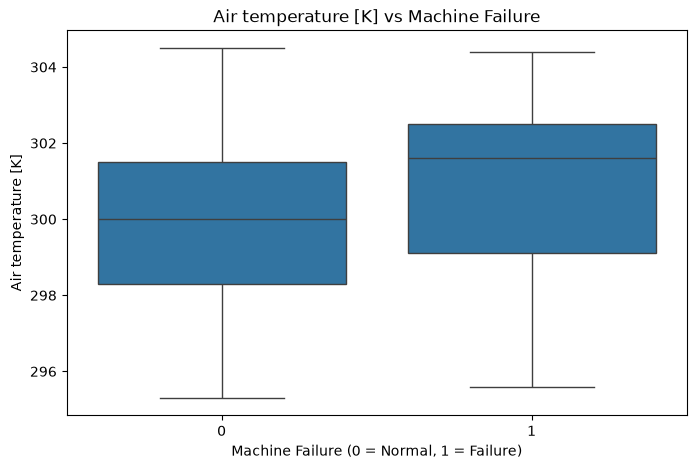

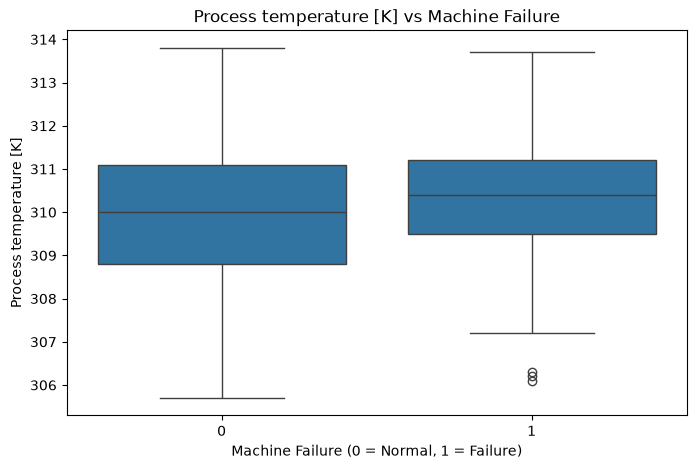

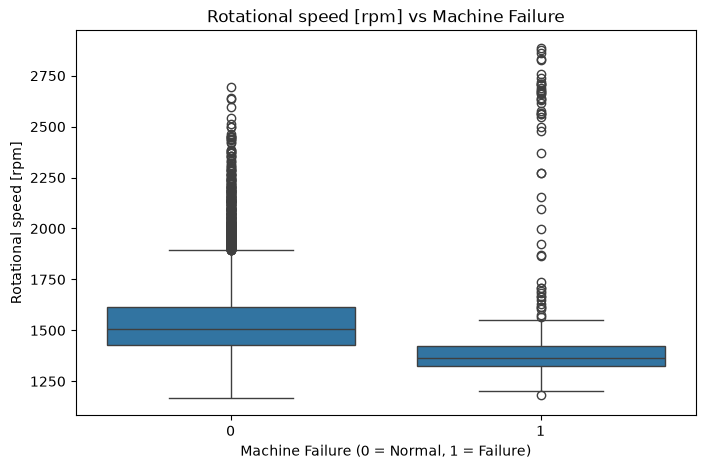

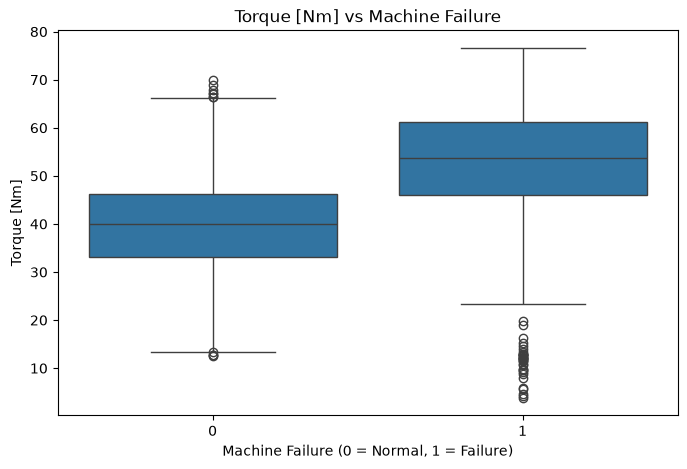

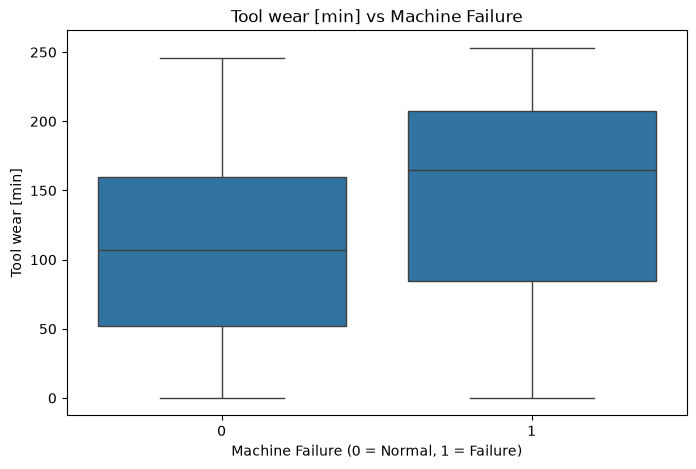

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for feature in features:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )
    
    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
    plt.ylabel(feature)
    plt.show()

In [10]:
df.groupby("Machine failure")[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


In [11]:
df[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure"
    ]
].corr()["Machine failure"].sort_values(ascending=False)

Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64

In [12]:
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_types].sum().sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [13]:
df[failure_types].mean().mul(100).sort_values(ascending=False)

HDF    1.15
OSF    0.98
PWF    0.95
TWF    0.46
RNF    0.19
dtype: float64

In [14]:
df["Temperature_difference"] = (
    df["Process temperature [K]"] - df["Air temperature [K]"]
)

df[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Temperature_difference",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]].head()

,Air temperature [K],Process temperature [K],Temperature_difference,Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,298.1,308.6,10.5,1551,42.8,0,0
1,298.2,308.7,10.5,1408,46.3,3,0
2,298.1,308.5,10.4,1498,49.4,5,0
3,298.2,308.6,10.4,1433,39.5,7,0
4,298.2,308.7,10.5,1408,40.0,9,0


In [15]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Temperature_difference",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

X.shape, y.shape

((10000, 6), (10000,))

In [16]:
X.head()

,Air temperature [K],Process temperature [K],Temperature_difference,Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,10.5,1551,42.8,0
1,298.2,308.7,10.5,1408,46.3,3
2,298.1,308.5,10.4,1498,49.4,5
3,298.2,308.6,10.4,1433,39.5,7
4,298.2,308.7,10.5,1408,40.0,9


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining failure rate:")
print(y_train.mean())

print("\nTesting failure rate:")
print(y_test.mean())

Training samples: (8000, 6)
Testing samples: (2000, 6)

Training failure rate:
0.033875

Testing failure rate:
0.034


In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [20]:
class_weight="balanced"

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Features
X = df[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Temperature_difference",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

# Target
y = df["Machine failure"]

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

# Model pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Training samples: (8000, 6)
Testing samples: (2000, 6)

Accuracy: 0.8215
ROC-AUC: 0.9079360004871514

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.84      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.82      0.88      2000


Confusion Matrix:
[[1586  346]
 [  11   57]]


In [5]:
import pandas as pd

df = pd.read_csv("../Data/Raw/ai4i2020.csv")
df["Temperature_difference"] = (
    df["Process temperature [K]"] - df["Air temperature [K]"]
)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Temperature_difference",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results
Accuracy: 0.9705
ROC-AUC: 0.9713189623675558

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      1932
           1       0.54      0.91      0.68        68

    accuracy                           0.97      2000
   macro avg       0.77      0.94      0.83      2000
weighted avg       0.98      0.97      0.97      2000


Confusion Matrix:
[[1879   53]
 [   6   62]]


In [12]:
# ============================================
# FORGEAI - XGBOOST FAILURE PREDICTION
# ============================================

# 1. Imports
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)
from xgboost import XGBClassifier


# ============================================
# 2. Define features and target
# ============================================

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"


# ============================================
# 3. Create X and y
# ============================================

X = df[features].copy()
y = df[target].copy()


# ============================================
# 4. Make feature names XGBoost-safe
# ============================================

X.columns = (
    X.columns
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("/", "_", regex=False)
)

print("Features:")
print(X.columns.tolist())


# ============================================
# 5. Train/Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining failure rate:", y_train.mean())
print("Testing failure rate:", y_test.mean())


# ============================================
# 6. Calculate scale_pos_weight
# ============================================

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("\nClass distribution:")
print("Normal:", negative)
print("Failure:", positive)

print("Scale pos weight:", scale_pos_weight)


# ============================================
# 7. Create XGBoost model
# ============================================

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    # Important because our dataset is imbalanced
    scale_pos_weight=scale_pos_weight,

    objective="binary:logistic",
    eval_metric="logloss",

    random_state=42,
    n_jobs=-1
)


# ============================================
# 8. Train model
# ============================================

xgb_model.fit(
    X_train,
    y_train
)


# ============================================
# 9. Predictions
# ============================================

xgb_pred = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]


# ============================================
# 10. Evaluation
# ============================================

print("\n")
print("XGBOOST RESULTS")
print("=" * 60)

accuracy = accuracy_score(
    y_test,
    xgb_pred
)

roc_auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("Accuracy:", accuracy)
print("ROC-AUC:", roc_auc)


# ============================================
# 11. Classification Report
# ============================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred
    )
)


# ============================================
# 12. Confusion Matrix
# ============================================

print("Confusion Matrix:")

cm = confusion_matrix(
    y_test,
    xgb_pred
)

print(cm)


# ============================================
# 13. Extract TP / TN / FP / FN
# ============================================

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix Breakdown:")
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)


# ============================================
# 14. Failure Detection Metrics
# ============================================

failure_recall = tp / (tp + fn)

failure_precision = tp / (tp + fp)

failure_f1 = (
    2 * failure_precision * failure_recall
    / (failure_precision + failure_recall)
)

print("\nFailure Detection Performance:")
print("Failure Precision:", failure_precision)
print("Failure Recall   :", failure_recall)
print("Failure F1 Score :", failure_f1)

Features:
['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min']

Training samples: (8000, 5)
Testing samples: (2000, 5)

Training failure rate: 0.033875
Testing failure rate: 0.034

Class distribution:
Normal: 7729
Failure: 271
Scale pos weight: 28.52029520295203


XGBOOST RESULTS
Accuracy: 0.9745
ROC-AUC: 0.9726510169285105

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.60      0.76      0.67        68

    accuracy                           0.97      2000
   macro avg       0.79      0.87      0.83      2000
weighted avg       0.98      0.97      0.98      2000

Confusion Matrix:
[[1897   35]
 [  16   52]]

Confusion Matrix Breakdown:
True Negatives : 1897
False Positives: 35
False Negatives: 16
True Positives : 52

Failure Detection Performance:
Failure Precision: 0.5977011494252874
Failure Recall   : 0.7647058823529411
Failure F1 

In [11]:
# ============================================
# FORGEAI - SHAP EXPLAINABILITY
# ============================================

import shap
import matplotlib.pyplot as plt

# --------------------------------------------
# 1. Create SHAP explainer
# --------------------------------------------

explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for test data. Some SHAP versions report a small
# additivity mismatch for tree classifiers; it does not prevent explanations.
shap_values = explainer.shap_values(X_test, check_additivity=False)

print("SHAP values calculated successfully.")


# --------------------------------------------
# 2. Check SHAP output
# --------------------------------------------

print("X_test shape:", X_test.shape)

if isinstance(shap_values, list):
    positive_class_shap_values = shap_values[1]
elif shap_values.ndim == 3:
    positive_class_shap_values = shap_values[:, :, 1]
else:
    positive_class_shap_values = shap_values

print("SHAP output shape:", positive_class_shap_values.shape)

SHAP values calculated successfully.
X_test shape: (2000, 5)
SHAP output shape: (2000, 5)


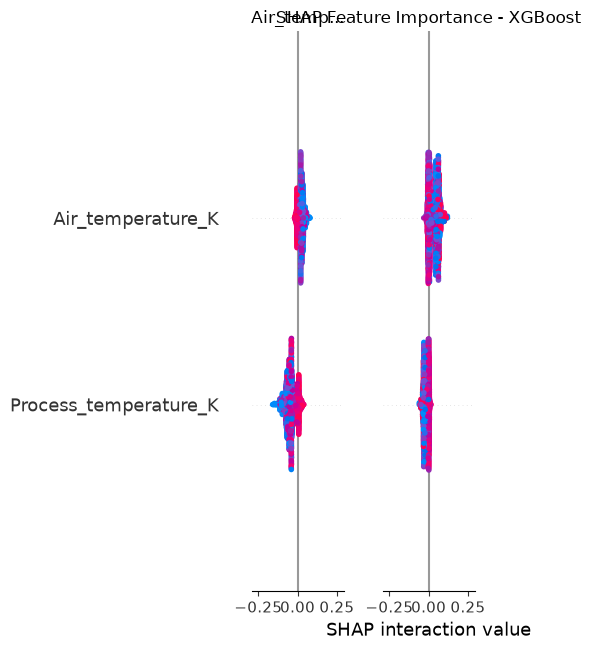

In [13]:
import matplotlib.pyplot as plt
import shap

# Global feature importance
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    show=False
)

plt.title("SHAP Feature Importance - XGBoost")
plt.tight_layout()
plt.show()

In [14]:
# Explain one specific machine
sample_idx = 100

sample = X_test.iloc[[sample_idx]]

print("Machine features:")
display(sample)

print("\nPredicted failure probability:")
print(xgb_model.predict_proba(sample)[0, 1])

Machine features:


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min
5953,300.7,310.9,1486,38.9,106



Predicted failure probability:
0.0021942474


IndexError: index 9 is out of bounds for axis 0 with size 5

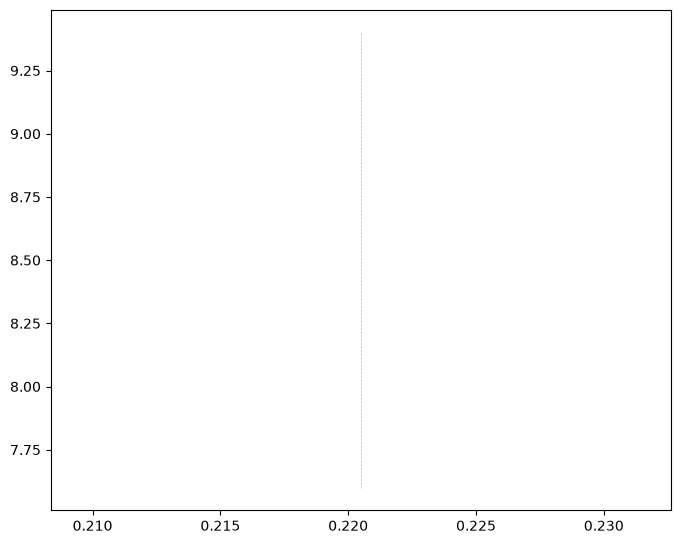

In [17]:
import numpy as np
import shap

# Select one machine
sample_idx = 100

# Select the positive-class values in the format returned by this SHAP version
if isinstance(shap_values, list):
    single_shap_values = np.asarray(shap_values[1])[sample_idx].flatten()
elif np.asarray(shap_values).ndim == 3:
    single_shap_values = np.asarray(shap_values)[sample_idx, :, 1].flatten()
else:
    single_shap_values = np.asarray(shap_values)[sample_idx].flatten()

# Get the machine's feature values
single_features = np.asarray(X_test.iloc[sample_idx]).flatten()

# Use the positive-class base value
expected_values = np.asarray(explainer.expected_value).flatten()
base_value = float(expected_values[1] if expected_values.size > 1 else expected_values[0])

# Create a single SHAP explanation
single_explanation = shap.Explanation(
    values=single_shap_values,
    base_values=base_value,
    data=single_features,
    feature_names=list(X_test.columns)
)

# Display waterfall plot
shap.plots.waterfall(single_explanation)

In [ ]:
# Persist production artifacts safely
from pathlib import Path
import json
import os
import joblib

if not hasattr(rf_model, "predict_proba") or not hasattr(rf_model, "classes_"):
    raise RuntimeError("rf_model must be fitted before exporting production artifacts")

feature_columns = list(X_train.columns)
if list(X_test.columns) != feature_columns:
    raise ValueError("Training and test feature columns do not match")
if len(feature_columns) != rf_model.n_features_in_:
    raise ValueError("Feature schema does not match the fitted model")

model_dir = Path("../models").resolve()
model_dir.mkdir(parents=True, exist_ok=True)

def atomic_joblib_dump(value, destination):
    temporary = destination.with_name(destination.name + ".tmp")
    try:
        joblib.dump(value, temporary, compress=3)
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()

model_path = model_dir / "random_forest_failure_model.pkl"
features_path = model_dir / "feature_columns.pkl"
metadata_path = model_dir / "random_forest_failure_model.json"

atomic_joblib_dump(rf_model, model_path)
atomic_joblib_dump(feature_columns, features_path)

metadata = {
    "model_type": "RandomForestClassifier",
    "model_file": model_path.name,
    "feature_file": features_path.name,
    "feature_columns": feature_columns,
    "classes": rf_model.classes_.tolist(),
    "n_features_in": int(rf_model.n_features_in_),
    "decision_threshold": 0.5
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print(f"Random Forest model saved to: {model_path}")
print(f"Feature columns saved to: {features_path}")
print(f"Model metadata saved to: {metadata_path}")